In [15]:
import numpy as np
import matplotlib.pyplot as plt
import k3d

Так как в алгоритме размещения я сперва разбиваю сферу на полосы по $\theta$, то я могу определить полосу попадания трека. Все полосы одинаковой ширины $\Delta \theta$. Если $\theta_i$ координата попадания трека, то номер полосы попадания:
$$n_\theta = \text{floor}\left(\frac{\theta_i}{\Delta \theta}\right)$$
По $\varphi$ в полосе все детекторы расположены равномерное с учетом начальной фазы $\phi_{0, n_\theta}$, а числе детекторов в полосе $N_{\varphi, n_\theta}$. Тогда если координата попадания трека $\varphi$, то номер ближайшего ФЭУ:
$$n_\phi = \frac{N_{\varphi, n_\theta}}{2\pi}(\varphi - \varphi_{0, n_\theta})$$
И теперь остается только сравнить расстояние от точки попадания до детектора. И это делается за O(1) время!!!

### Detector class

In [16]:
class Detector():
    def __init__(self, R: float, N: int, r: float, a: float):
        """
        Parameters
        ----------
        R : float
            Радиус детектора в метрах.
        N : int
            Количество фотоумножителей.
        r : float
            Радиус фотокатода в метрах.
        a : float
            Эффективность фотокатода.
        """
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.rng = np.random.default_rng()

    def coord_cart(self, theta: float, phi: float) -> np.ndarray:
        return np.array([self.R * np.sin(theta)*np.cos(phi), self.R * np.sin(theta)*np.sin(phi), self.R*np.cos(theta)])

    def fill_detector(self):
        self.photo_multipliers = np.zeros((self.N, 3))
        S = 4 * self.R**2 * np.pi 
        delta_S = S / self.N 
        lin_size = delta_S**0.5 
        N_theta = np.pi * self.R / lin_size 
        delta_theta = np.pi / N_theta

        theta_floor = [int(np.floor(N_theta)), np.pi / np.floor(N_theta), delta_theta - np.pi / np.floor(N_theta)]
        theta_ceil = [int(np.ceil(N_theta)), np.pi / np.ceil(N_theta), delta_theta - np.pi / np.ceil(N_theta)]

        best_theta = min(theta_floor, theta_ceil, key=lambda x: abs(x[2]))
        N_theta, delta_theta = best_theta[0], best_theta[1]
        self.delta_theta = delta_theta

        mid_thetas = np.array([delta_theta / 2 + delta_theta*i for i in range(0, N_theta)])
        self.thetas = mid_thetas
        n_phi = np.array([(np.pi * self.N)**0.5*np.sin(theta) for theta in mid_thetas])

        A = self.N / sum([np.sin(theta) for theta in mid_thetas])
        n_phi = np.rint(np.array([A * np.sin(theta) for theta in mid_thetas])) #-> (3, 7, 10, 10, 7, 3)
        #n_phi = np.array([2, 7, 11, 11, 7, 2])  
        self.n_phis = n_phi.astype(int) 
        self.detectors_before = np.zeros(N_theta).astype(int)
        n = 0
        for i in range(N_theta):
            self.detectors_before[i] = n
            n += n_phi[i]

        phi_phases = np.zeros(N_theta)
        for i in range(N_theta):
            if i == 0:
                continue
            phi_phases[i] = np.pi / np.lcm(int(n_phi[i-1]), int(n_phi[i]))
        self.phis = np.zeros(N_theta)
        n = 0
        phase = 0
        for i in range(N_theta):
            if i < N_theta/2:
                phase += phi_phases[i]
            else:
                phase -= phi_phases[i]
            self.phis[i] = phase
            for j in range(int(n_phi[i])):
                self.photo_multipliers[n] = self.coord_cart(mid_thetas[i], 2*np.pi/n_phi[i] * j + phase)
                n += 1

    def in_chord(self, coord: np.ndarray) -> int:
        for k, photo_multiplier in enumerate(self.photo_multipliers):
            distance = np.linalg.norm(photo_multiplier-coord)
            if distance <= self.r:
                return k
        return -1

    def register_many(self, hits: np.ndarray) -> int:
        diff = hits[:, None, :] - self.photo_multipliers[None, :, :]
        distances2 = np.sum(diff**2, axis=2)

        hit_mask = distances2 <= self.r**2

        photons_per_pmt = np.sum(hit_mask, axis=0)

        charge_per_pmt = self.rng.poisson(lam=self.a * photons_per_pmt)

        return np.sum(charge_per_pmt)
    
    def fast_register(self, hits: np.ndarray) -> int:
        hits_thetas = np.arccos(hits[:, 2]/self.R)
        hits_phis = np.arctan2(hits[:, 1], hits[:, 0])
        theta_indices = np.clip(np.floor(hits_thetas / self.delta_theta).astype(int), 0, len(self.n_phis) - 1)
        phi_indices = np.rint(self.n_phis[theta_indices] / (2 * np.pi) * (hits_phis - self.phis[theta_indices])).astype(int) % self.n_phis[theta_indices]
        photo_multiplier_ids = self.detectors_before[theta_indices] + phi_indices
        photo_multiplier_coords = self.photo_multipliers[photo_multiplier_ids]
        distances2 = np.sum((hits - photo_multiplier_coords)**2, axis=1)
        mask = distances2 <= self.r**2

        photons_per_pmt = np.sum(mask, axis=0)
        
        charge_per_pmt = self.rng.poisson(lam=self.a * photons_per_pmt)
        return np.sum(charge_per_pmt)



### Source class

In [17]:
class Source:
    def __init__(self):
        """
        Parameters
        ----------
        pos : np.array
            координаты источника
        """
        self.Y = 10000 
        self.rng = np.random.default_rng()


    def sphere(self, R: float) -> np.ndarray: #взял метод из ROOT
        r2 = 1.0

        while r2 > 0.25:
            a = np.random.random() - 0.5
            b = np.random.random() - 0.5
            r2 = a**2 + b**2

        z = R * (-1.0 + 8.0 * r2)
        scale = 8.0 * R * np.sqrt(0.25 - r2)

        x = a * scale
        y = b * scale

        point = np.array([x, y, z])

        return point

    def generate_photons(self, E: float) -> np.ndarray:
        photon_number = int(E * self.Y)
        photons = np.zeros((photon_number, 3))
        for i in range(photon_number):
            photons[i] = self.sphere(1.0)
        return photons

    def generate_photons_vec(self, E: float):
        photon_number = self.rng.poisson(E * self.Y)
        while photon_number > 0:
            portion_size = min(100, photon_number)
            photon_number -= portion_size
            phi = self.rng.uniform(0, 2*np.pi, portion_size)
            cos_theta = self.rng.uniform(-1, 1, portion_size)
            sin_theta = np.sqrt(1 - cos_theta**2)
            photons = np.column_stack((sin_theta * np.cos(phi), sin_theta * np.sin(phi), cos_theta))

            yield photons

### Задача 8

In [18]:
def photon_propagation_vec(pos: np.ndarray, directions: np.ndarray, R: float) -> np.ndarray:
    nr = directions @ pos
    r2 = np.dot(pos, pos)

    t = -nr + np.sqrt(nr**2 - (r2 - R**2))

    hits = pos + directions * t[:, None]

    return hits

def photon_decay_propagation_vec(pos: np.ndarray, directions: np.ndarray, R: float, L: float) -> np.ndarray:
    nr = directions @ pos
    r2 = np.dot(pos, pos)

    t = -nr + np.sqrt(nr**2 - (r2 - R**2))
    probs = np.random.uniform(0, 1, len(t))
    exps = np.exp(-t / L)
    mask = exps > probs
    hits = pos + directions * t[:, None]

    return hits[mask]

In [19]:
R = 15
N = 2000
r = 0.1
a = 0.5
decay_lenght = 8

detector = Detector(R, N, r, a)
detector.fill_detector()
source = Source()

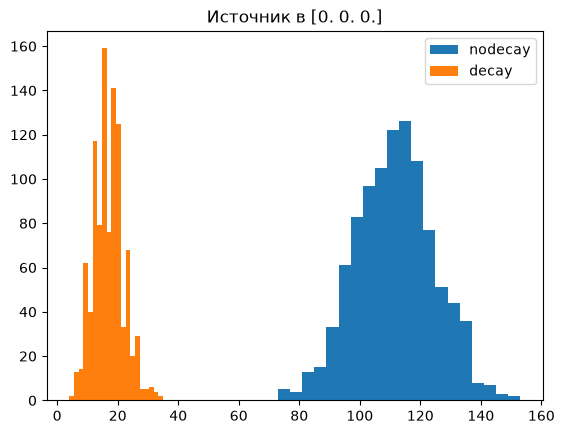

среднее и стандартное отклонение без распада 111.189, 12.988582640149772
среднее и стандартное отклонение с распадом 16.995, 4.964169114766337


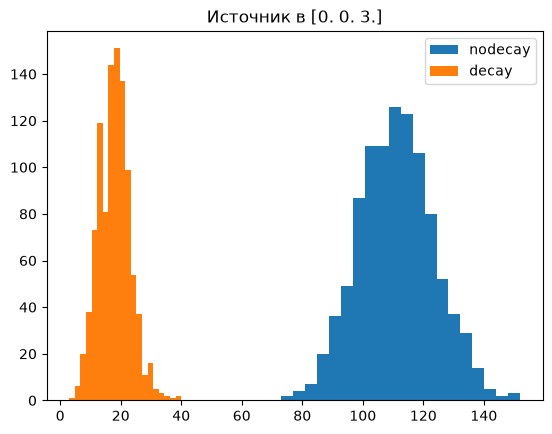

среднее и стандартное отклонение без распада 111.107, 12.592043162251311
среднее и стандартное отклонение с распадом 17.951, 5.183300010611001


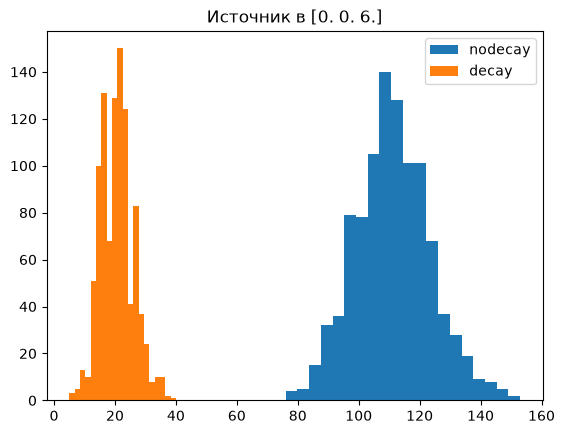

среднее и стандартное отклонение без распада 111.235, 12.459766249813837
среднее и стандартное отклонение с распадом 20.491, 5.392394551588376


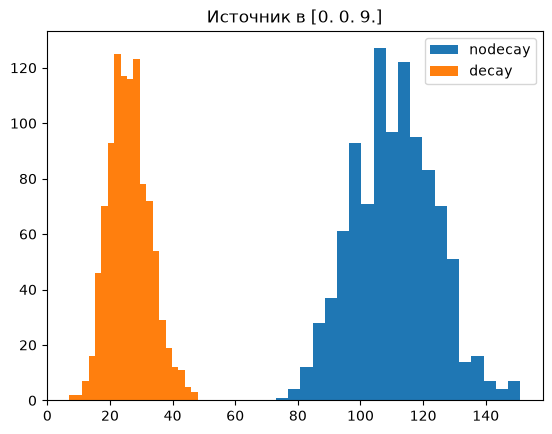

среднее и стандартное отклонение без распада 110.766, 13.061441114976555
среднее и стандартное отклонение с распадом 26.277, 6.40330157028388


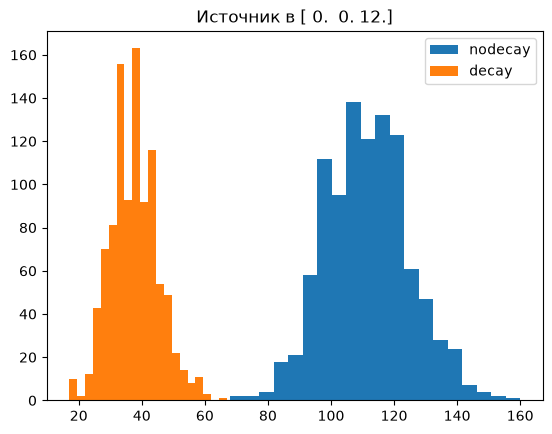

среднее и стандартное отклонение без распада 111.387, 13.336087544703657
среднее и стандартное отклонение с распадом 37.379, 7.547009937717056


In [20]:
N_event = 1000
energy = 1
positions = np.array([[0, 0, 0.1 * R * i] for i in range(0, 9, 2)])
results = {}

for p, position in enumerate(positions):
    charges_no_decay = np.zeros(N_event)
    charges_decay = np.zeros(N_event)
    for event in range(N_event):
        photons = source.generate_photons_vec(energy)
        for portion in photons:
            hits_no_decay = photon_propagation_vec(position, portion, detector.R)
            hits_decay = photon_decay_propagation_vec(position, portion, detector.R, decay_lenght)
            charges_no_decay[event] += detector.fast_register(hits_no_decay)
            charges_decay[event] += detector.fast_register(hits_decay)

    results[(p, energy, 'nodecay')] = charges_no_decay
    results[(p, energy, 'decay')] = charges_decay
    plt.figure()
    plt.hist(results[(p, energy, 'nodecay')], bins=20, label='nodecay')
    plt.hist(results[(p, energy, 'decay')], bins=20, label='decay')
    plt.legend()
    plt.title(f'Источник в {position}')
    plt.show()
    print(f'среднее и стандартное отклонение без распада {np.mean(results[(p, energy, 'nodecay')])}, {np.std(results[(p, energy, 'nodecay')])}')
    print(f'среднее и стандартное отклонение с распадом {np.mean(results[(p, energy, 'decay')])}, {np.std(results[(p, energy, 'decay')])}')

In [21]:
plot = k3d.plot()
points = k3d.points(detector.photo_multipliers,point_size=0.2)

plot += points
plot.display()

Output()